In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [2]:
loader = HFDatasetLoader(
    dataset_name="psabino/precios_de_viviendas_madrid",
    split="train",
    filename="datos/apartment_price_ml_regressionlineal.csv",
)

In [20]:
df = loader.load()
df.head(5)

,url,url_listado,titulo,id,precio,baños,habitaciones,metros_cuadrados,descripcion,direccion,tipologia,nombre_anunciante_profesional,nombre_anunciante
0,https://www.idealista.com/inmueble/104027174/,https://www.idealista.com/venta-viviendas/madr...,Piso en venta en calle de Villanueva,104027174,1920000,3,3,183,Residencia única con acabados de la más alta c...,"Recoletos, Madrid",Pisos,Promora Madrid,Promora Madrid
1,https://www.idealista.com/inmueble/102321942/,https://www.idealista.com/venta-viviendas/madr...,Piso en venta en calle de Núñez de Balboa,102321942,1995000,3,3,170,"Preciosa reforma a estrenar, con terrazas y ga...","Castellana, Madrid",Pisos,Madrid MMC,Engel & Völkers Madrid
2,https://www.idealista.com/inmueble/103334142/,https://www.idealista.com/venta-viviendas/madr...,Piso en venta en Conde Orgaz-Piovera,103334142,1300000,3,4,270,DE SALAS CONSULTORES INMOBILIARIOS MAV02679 le...,"Hortaleza, Madrid",Pisos,De Salas Consultores Inmobiliarios,De Salas Consultores Inmobiliarios
3,https://www.idealista.com/inmueble/104161987/,https://www.idealista.com/venta-viviendas/madr...,Piso en venta en Nueva España,104161987,1650000,3,3,248,Gilmar Real Estate vende espectacular piso en ...,"Chamartín, Madrid",Pisos,departamento comercial,Gilmar Viso - Chamartín
4,https://www.idealista.com/inmueble/103989666/,https://www.idealista.com/venta-viviendas/madr...,Piso en venta en calle de Claudio Coello,103989666,1590750,3,3,116,Descubre esta impresionante vivienda exterior ...,"Recoletos, Madrid",Pisos,Walter Haus Salamanca,Walter Haus Madrid


## Regresion lineal simple

In [5]:
df["metros_cuadrados"].head()

0    183
1    170
2    270
3    248
4    116
Name: metros_cuadrados, dtype: int64

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = df[["metros_cuadrados"]], df["precio"] # preparar datos
modelo = LinearRegression() #inicializar modelo

X_train, X_test, y_train, y_test = train_test_split( #dividir_datos
    X, y, test_size=0.2, random_state=42
)

modelo.fit(X_train, y_train)# entrenamiento
predicciones = modelo.predict(X_test) # prediccion
w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w:.2f}")
print(f"b: {b:.2f}")

MAE: 469878.62
RMSE: 616040.48
R2: 0.51
w: 3579.45
b: 520990.92


In [7]:
%pip install --upgrade matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 32.2 MB/s  0:00:00a 0:00:01
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.9.4
    Uninstalling matplotlib-3.9.4:
      Successfully uninstalled matplotlib-3.9.4
Note: you may need to restart the kernel to use updated packages.


In [8]:
%matplotlib inline

In [9]:
import sys
import matplotlib

print(sys.executable)
print(matplotlib.__version__)

/workspaces/ML_EA2_202610/.venv/bin/python
3.11.2


In [10]:
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["metros_cuadrados"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()



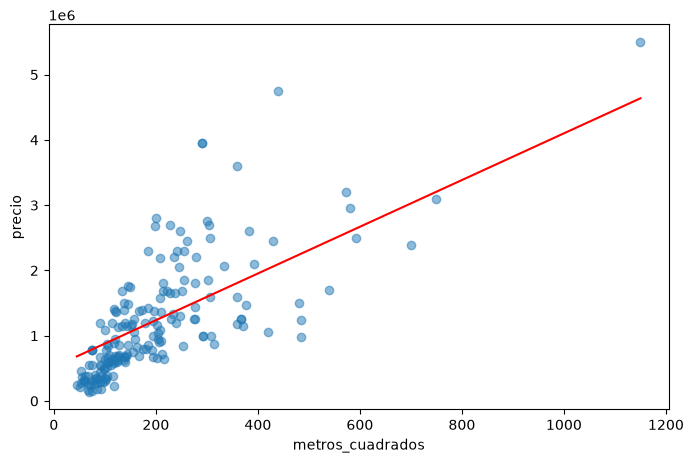

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

ax.plot(
    x_test[orden],
    predicciones[orden],
    color="red",
)

ax.set_xlabel("metros_cuadrados")
ax.set_ylabel("precio")

display(fig)
plt.close(fig)

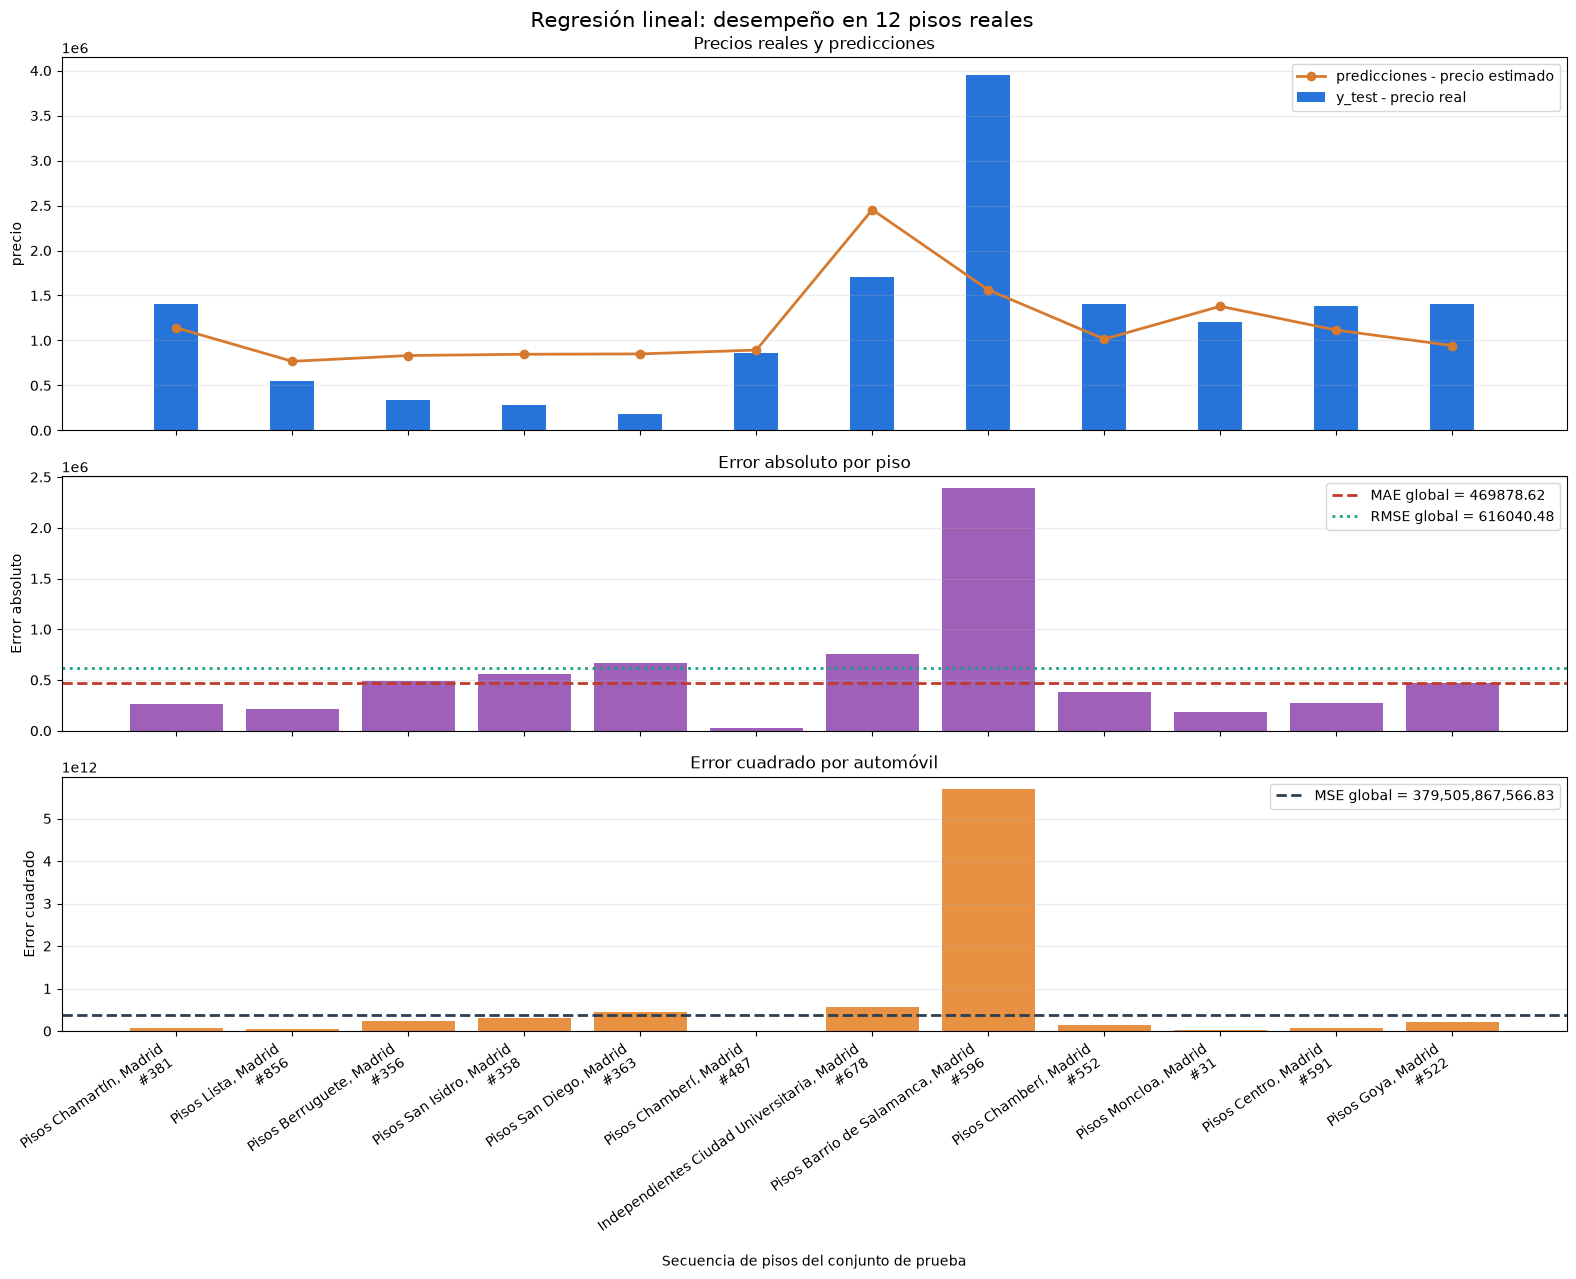

Automóviles mostrados: 12 de 183
Métricas globales - MAE: 469878.62; RMSE: 616040.48; MSE: 379,505,867,566.83
Métricas de la selección - MAE: 556187.98; RMSE: 809489.68; MSE: 655,273,546,193.03


In [15]:
# Comparación combinada para una selección legible de automóviles reales
indices_test = y_test.index.to_numpy()
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Se muestran 12 automóviles, manteniendo el orden del conjunto de prueba.
seleccion = np.arange(min(12, len(y_test_array)))
y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]
errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2
etiquetas = [
    f"{df.loc[indices_test[i], 'tipologia']} {df.loc[indices_test[i], 'direccion']}\n#{indices_test[i] + 1}"
    for i in seleccion
]

mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)
posiciones = np.arange(len(seleccion))
ancho = 0.38

fig, (ax_precios, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1, figsize=(16, 13), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]},
)

# Arriba: precio real en barras y predicción como línea con puntos.
ax_precios.bar(posiciones, y_real, ancho, label="y_test - precio real", color="#2674d9")
ax_precios.plot(posiciones, y_predicha, color="#d67a2f", marker="o", linewidth=2,
                label="predicciones - precio estimado")
ax_precios.set_ylabel("precio")
ax_precios.set_title("Precios reales y predicciones")
ax_precios.legend()
ax_precios.grid(axis="y", alpha=0.25)

# En medio: errores absolutos y referencias globales del modelo.
ax_absoluto.bar(posiciones, error_absoluto, color="#8e44ad", alpha=0.85)
ax_absoluto.axhline(mae_global, color="#c0392b", linestyle="--", linewidth=2,
                    label=f"MAE global = {mae_global:.2f}")
ax_absoluto.axhline(rmse_global, color="#16a085", linestyle=":", linewidth=2,
                    label=f"RMSE global = {rmse_global:.2f}")
ax_absoluto.set_ylabel("Error absoluto")
ax_absoluto.set_title("Error absoluto por piso")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)

# Abajo: errores cuadrados y referencia global del MSE.
ax_cuadrado.bar(posiciones, error_cuadrado, color="#e67e22", alpha=0.85)
ax_cuadrado.axhline(mse_global, color="#2c3e50", linestyle="--", linewidth=2,
                    label=f"MSE global = {mse_global:,.2f}")
ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por automóvil")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)

ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("Secuencia de pisos del conjunto de prueba")
fig.suptitle("Regresión lineal: desempeño en 12 pisos reales", fontsize=15)
fig.tight_layout()
display(fig)
plt.close(fig)

print(f"Automóviles mostrados: {len(seleccion)} de {len(y_test_array)}")
print(f"Métricas globales - MAE: {mae_global:.2f}; RMSE: {rmse_global:.2f}; MSE: {mse_global:,.2f}")
print(f"Métricas de la selección - MAE: {error_absoluto.mean():.2f}; RMSE: {np.sqrt(error_cuadrado.mean()):.2f}; MSE: {error_cuadrado.mean():,.2f}")


Filas: 915 | duplicados exactos: 0
Valores faltantes por columna:
Sin valores faltantes


/tmp/ipykernel_35233/3744269789.py:43: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  prueba["error_absoluto"] = np.abs(
/tmp/ipykernel_35233/3744269789.py:47: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You ar

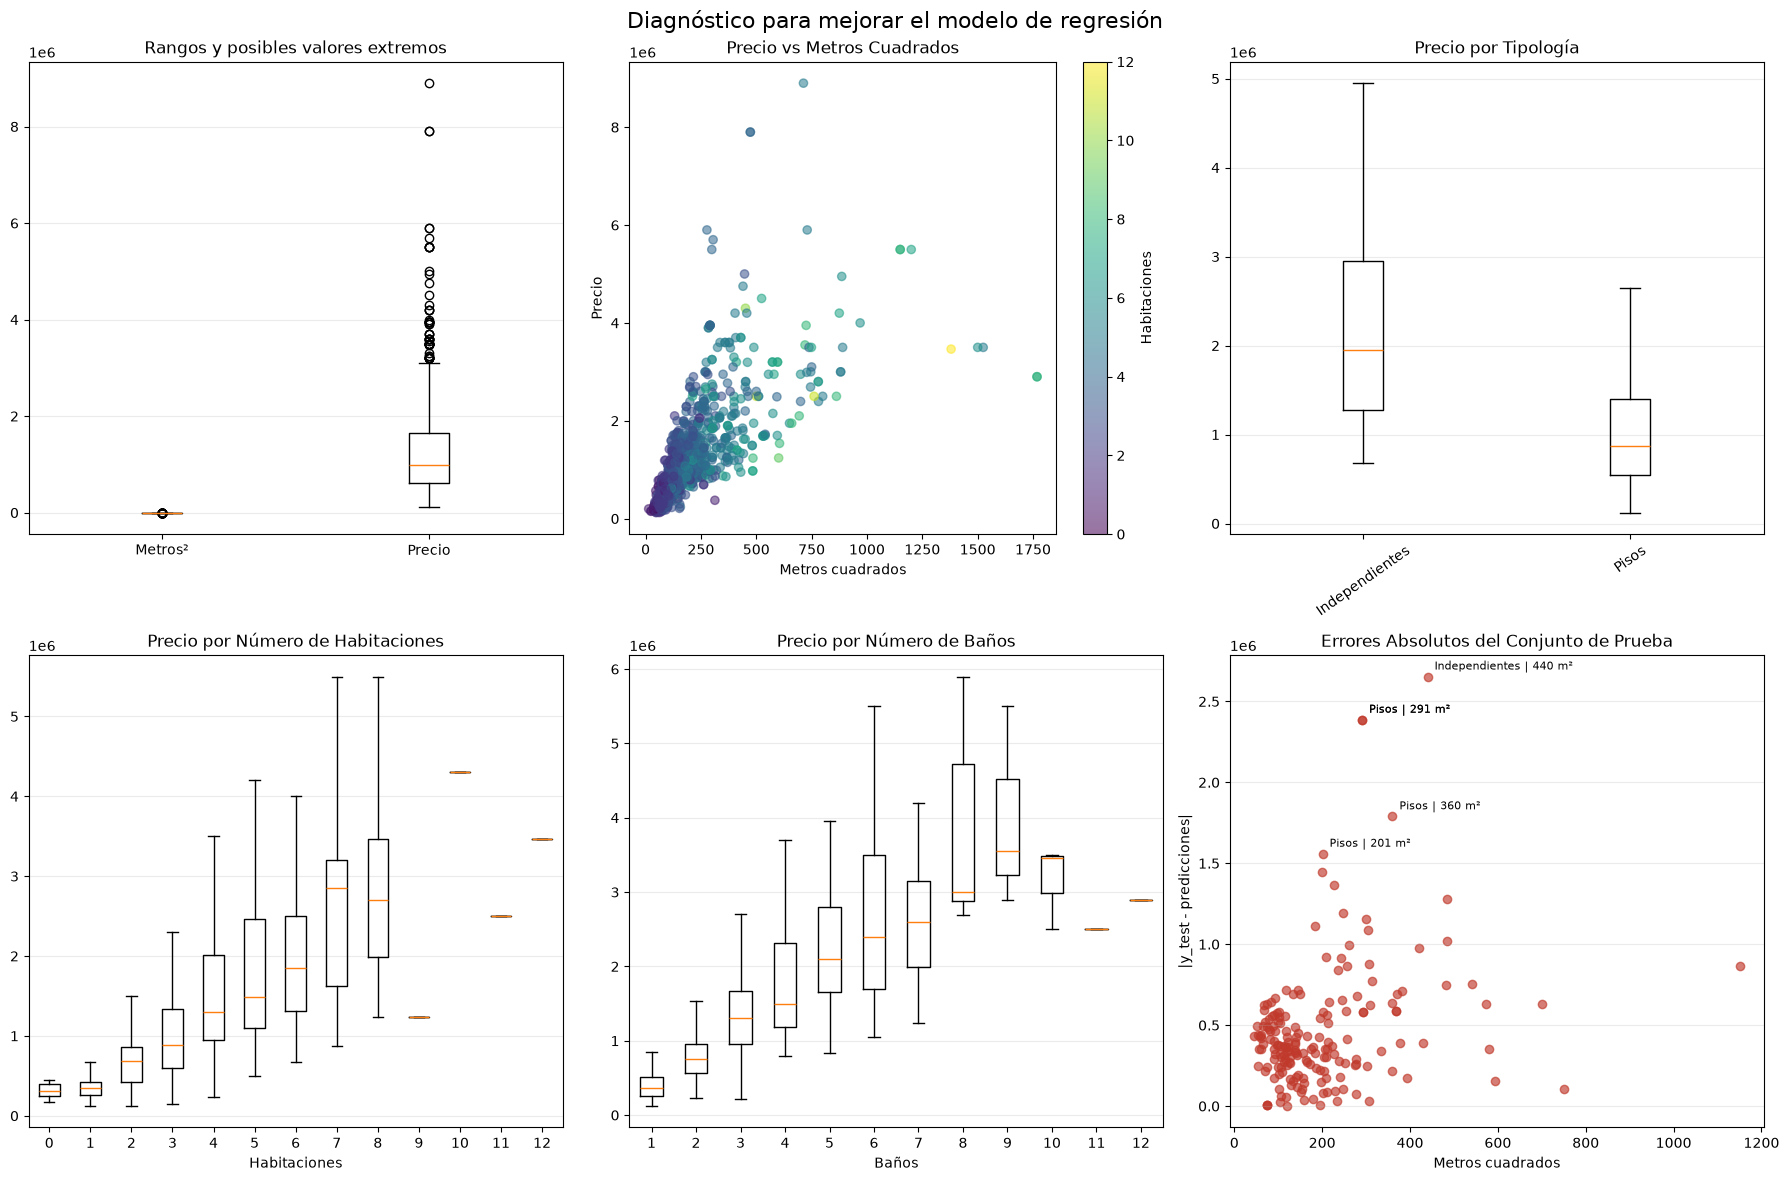


Mayores errores absolutos del conjunto de prueba:
          tipologia  habitaciones  baños  metros_cuadrados   y_test  predicciones  error_absoluto
720  Independientes             5      6               440  4750000  2.095948e+06    2.654052e+06
595           Pisos             4      5               291  3950000  1.562610e+06    2.387390e+06
900           Pisos             4      5               291  3950000  1.562610e+06    2.387390e+06
327           Pisos             5      4               360  3600000  1.809592e+06    1.790408e+06
77            Pisos             4      3               201  2800000  1.240460e+06    1.559540e+06

Cobertura de categorías:
tipologia: 2 categorías | mínimo por categoría: 136
direccion: 105 categorías | mínimo por categoría: 1


In [16]:
# Diagnóstico visual para identificar oportunidades de mejora del modelo
# y analizar la calidad de las predicciones sobre inmuebles.

columnas_requeridas = [
    "precio",
    "baños",
    "habitaciones",
    "metros_cuadrados",
    "direccion",
    "tipologia"
]

# Conservar únicamente las columnas que realmente existen en el DataFrame
columnas_disponibles = [
    columna for columna in columnas_requeridas
    if columna in df.columns
]

# Diagnóstico inicial de calidad de datos
filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()

print(f"Filas: {len(df)} | duplicados exactos: {filas_duplicadas}")
print("Valores faltantes por columna:")
print(
    valores_faltantes[valores_faltantes > 0]
    if valores_faltantes.any()
    else "Sin valores faltantes"
)

# ============================================================
# Preparación del conjunto de prueba para analizar errores
# ============================================================

indices_test = y_test.index.to_numpy()

prueba = df.loc[indices_test, columnas_disponibles].copy(deep=True)

prueba["y_test"] = y_test.to_numpy()
prueba["predicciones"] = np.asarray(predicciones)

# Error absoluto y error cuadrático
prueba["error_absoluto"] = np.abs(
    prueba["y_test"] - prueba["predicciones"]
)

prueba["error_cuadrado"] = (
    prueba["y_test"] - prueba["predicciones"]
) ** 2

# ============================================================
# Creación del panel de gráficos de diagnóstico
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# ------------------------------------------------------------
# 1. Detección de valores extremos
# ------------------------------------------------------------

axes[0, 0].boxplot(
    [
        df["metros_cuadrados"].dropna(),
        df["precio"].dropna()
    ],
    tick_labels=["Metros²", "Precio"],
    showfliers=True,
)

axes[0, 0].set_title(
    "Rangos y posibles valores extremos"
)

axes[0, 0].grid(axis="y", alpha=0.25)

# ------------------------------------------------------------
# 2. Relación entre precio y tamaño
# Color = número de habitaciones
# ------------------------------------------------------------

scatter = axes[0, 1].scatter(
    df["metros_cuadrados"],
    df["precio"],
    c=df["habitaciones"],
    cmap="viridis",
    alpha=0.55
)

axes[0, 1].set_title(
    "Precio vs Metros Cuadrados"
)

axes[0, 1].set_xlabel("Metros cuadrados")
axes[0, 1].set_ylabel("Precio")

fig.colorbar(
    scatter,
    ax=axes[0, 1],
    label="Habitaciones"
)

# ------------------------------------------------------------
# 3. Comparación de precios por tipología
# ------------------------------------------------------------

tipologias = sorted(
    df["tipologia"].dropna().unique()
)

axes[0, 2].boxplot(
    [
        df.loc[
            df["tipologia"] == tipo,
            "precio"
        ].dropna()
        for tipo in tipologias
    ],
    tick_labels=tipologias,
    showfliers=False,
)

axes[0, 2].set_title(
    "Precio por Tipología"
)

axes[0, 2].tick_params(
    axis="x",
    rotation=35
)

axes[0, 2].grid(
    axis="y",
    alpha=0.25
)

# ------------------------------------------------------------
# 4. Comparación de precios por habitaciones
# ------------------------------------------------------------

habitaciones = sorted(
    df["habitaciones"].dropna().unique()
)

axes[1, 0].boxplot(
    [
        df.loc[
            df["habitaciones"] == hab,
            "precio"
        ].dropna()
        for hab in habitaciones
    ],
    tick_labels=habitaciones,
    showfliers=False,
)

axes[1, 0].set_title(
    "Precio por Número de Habitaciones"
)

axes[1, 0].set_xlabel("Habitaciones")

axes[1, 0].grid(
    axis="y",
    alpha=0.25
)

# ------------------------------------------------------------
# 5. Comparación de precios por baños
# ------------------------------------------------------------

banos = sorted(
    df["baños"].dropna().unique()
)

axes[1, 1].boxplot(
    [
        df.loc[
            df["baños"] == bano,
            "precio"
        ].dropna()
        for bano in banos
    ],
    tick_labels=banos,
    showfliers=False,
)

axes[1, 1].set_title(
    "Precio por Número de Baños"
)

axes[1, 1].set_xlabel("Baños")

axes[1, 1].grid(
    axis="y",
    alpha=0.25
)

# ------------------------------------------------------------
# 6. Análisis de errores del modelo
# ------------------------------------------------------------

prueba_ordenada = prueba.sort_values(
    "error_absoluto",
    ascending=False
)

axes[1, 2].scatter(
    prueba["metros_cuadrados"],
    prueba["error_absoluto"],
    color="#c0392b",
    alpha=0.65
)

axes[1, 2].set_title(
    "Errores Absolutos del Conjunto de Prueba"
)

axes[1, 2].set_xlabel(
    "Metros cuadrados"
)

axes[1, 2].set_ylabel(
    "|y_test - predicciones|"
)

axes[1, 2].grid(
    axis="y",
    alpha=0.25
)

# Etiquetar los 5 inmuebles con mayor error
for indice, fila in prueba_ordenada.head(5).iterrows():

    axes[1, 2].annotate(
        (
            f"{df.loc[indice, 'tipologia']} | "
            f"{df.loc[indice, 'metros_cuadrados']} m²"
        ),
        (
            fila["metros_cuadrados"],
            fila["error_absoluto"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

# ============================================================
# Ajustes generales de la figura
# ============================================================

fig.suptitle(
    "Diagnóstico para mejorar el modelo de regresión",
    fontsize=16
)

fig.tight_layout()

display(fig)

plt.close(fig)

# ============================================================
# Mostrar los registros con mayor error
# ============================================================

print("\nMayores errores absolutos del conjunto de prueba:")

print(
    prueba_ordenada[
        [
            "tipologia",
            "habitaciones",
            "baños",
            "metros_cuadrados",
            "y_test",
            "predicciones",
            "error_absoluto"
        ]
    ]
    .head(5)
    .to_string()
)

# ============================================================
# Cobertura de categorías
# Permite identificar categorías con pocas observaciones
# ============================================================

print("\nCobertura de categorías:")

for columna in [
    "tipologia",
    "direccion"
]:

    print(
        f"{columna}: "
        f"{df[columna].nunique()} categorías | "
        f"mínimo por categoría: "
        f"{df[columna].value_counts().min()}"
    )

#### Preparar Datos

X, y = regresion.preparar_datos(df) # 
    def preparar_datos(
        self,
        df: pd.DataFrame,
        X_columnas: str | list[str] | tuple[str, ...],
        y_objetivo: str,
    ) -> tuple[pd.DataFrame, pd.Series]:

X_train, X_test, y_train, y_test = regresion.dividir_datos(X, y)
    def dividir_datos(
        X: pd.DataFrame,
        y: pd.Series,
        test_size: float = 0.2,
        random_state: int = 42,
    ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
modelo = regresion.entrenar(X_train, y_train)
    def entrenar(
        self,
        X_train: pd.DataFrame,
        y_train: pd.Series,
        directorio_entrenamiento: str | Path = "entrenamiento",
    ) -> dict[str, Any]:

predicciones = regresion.predecir(modelo, X_test)
    def predecir(
        self,
        ruta_modelo: str | Path,
        X_test: float | int | list[float] | tuple[float, ...] | pd.DataFrame,
    ) -> np.ndarray:

parametros = regresion.obtener_parametros(modelo)
    def obtener_parametros(
        self, ruta_modelo: str | Path
    ) -> dict[str, float | list[float]]:

metricas = regresion.evaluar(y_test, predicciones)
    def evaluar(
        self,
        ruta_modelo: str | Path,
        X_test: float | int | list[float] | tuple[float, ...] | pd.DataFrame,
        y_test: pd.Series,
    ) -> dict[str, float]:

In [17]:
from clases_po import RegresionLineal

In [21]:
regresion_simple = RegresionLineal(feature_column = "metros_cuadrados",target_column = "precio",test_size = 0.2, random_state =42)

In [23]:
X2, y2 = regresion_simple.preparar_datos(df=df,X_columnas=["habitaciones","metros_cuadrados"],y_objetivo="precio")

[preparar_datos] X=['habitaciones', 'metros_cuadrados'], y='precio'; 915 filas válidas; 0 filas eliminadas; X=(915, 2), y=(915,).


In [24]:
X2_train, X2_test, y2_train, y2_test =regresion_simple.dividir_datos(X= X2,y=y2,test_size = 0.2,random_state = 42)

[dividir_datos] test_size=0.20; random_state=42; entrenamiento=732 filas (732, 2); prueba=183 filas (183, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.


In [25]:
datos_entrenamiento = regresion_simple.entrenar(X_train=X2_train,y_train=y2_train,directorio_entrenamiento = "entrenamiento")

[entrenar] modelo ajustado con 732 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261025_223642_382189_modelo.pkl


In [26]:
datos_entrenamiento["ruta_modelo"]

PosixPath('entrenamiento/20261025_223642_382189_modelo.pkl')

In [27]:
algo=regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['habitaciones', 'metros_cuadrados'], y='precio'; 915 filas válidas; 0 filas eliminadas; X=(915, 2), y=(915,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=732 filas (732, 2); prueba=183 filas (183, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 732 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261025_223653_997390_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261025_223653_997390_modelo.pkl; 183 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261025_223653_997390_modelo.pkl; w=[110677.60198366958, 2942.0800889787993]; b=275273.1419.
[ejecutar][6/6] Iniciando evaluar.
[predeci

### Multiple

In [33]:
regresion_multiple = RegresionLineal(feature_column = ["habitaciones","metros_cuadrados"],target_column = "precio",test_size = 0.2, random_state =42)

In [34]:
algo2=regresion_multiple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['habitaciones', 'metros_cuadrados'], y='precio'; 915 filas válidas; 0 filas eliminadas; X=(915, 2), y=(915,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=732 filas (732, 2); prueba=183 filas (183, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 732 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento/20261025_223818_278423_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261025_223818_278423_modelo.pkl; 183 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261025_223818_278423_modelo.pkl; w=[110677.60198366958, 2942.0800889787993]; b=275273.1419.
[ejecutar][6/6] Iniciando evaluar.
[predeci

In [35]:
print(algo['metricas']['r2'])
print(algo2['metricas']['r2'])

0.5018068604541974
0.5018068604541974
